# Connection: from an event source to a placed synapse

This tutorial pairs with [synapse.ipynb](../synapse/synapse.ipynb). That one creates the postsynaptic dynamical entities; this one starts from an existing `SynapseView` and covers only how events reach a synapse through a Connection.

The underlying relation is always `EventSource -> Connection -> Synapse`. This tutorial uses the general low-level entry point `braincell.connect()` and leaves out the Network's place-and-connect shortcuts.

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import braincell
from braincell import mech
from braincell.filter import AllRegion, at

brainstate.environ.set(precision=64)

## 1. Three kinds of object and one Connection row

| Layer | User object | Holds | Role |
|---|---|---|---|
| source | `EventSource` / `EventSourceView` | a schedule or a live detector | produces discrete events |
| routing | `ConnectionView` | source ID, synapse ID, `weight`, `delay` | routes events to their targets |
| target | `SynapseView` / runtime SoA | parameters and states such as `tau`, `e`, `g` | consumes events and advances the dynamics |

Routing record $c$ can be written as

$$r_c=(s_c, j_c, w_c, d_c),$$

where $s_c$ is the source endpoint, $j_c$ the logical synapse, and $w_c$ and $d_c$ the event payload and the delay. Several rows may point to the same $j_c$; scalar payloads that reach the same synapse at the same time boundary are summed on that synapse.

`connect(...)` takes a concrete source owner or view and a `SynapseView` that is already placed; it does not take a location declaration that has not been instantiated. All views are lightweight indices that keep order and repeats and do not copy the underlying columns.

## 2. A minimal but runnable postsynaptic Cell

The cell below has the same kind of three-branch 3D morphology as [synapse.ipynb](../synapse/synapse.ipynb). Four population members share the morphology and the CV layout; `CableProperty + IL` make a real passive membrane, which the `staggered` solver advances in the last section.

In [2]:
soma = braincell.Branch.from_points(
    points=np.asarray([[-10.0, 0.0, 0.0], [10.0, 0.0, 0.0]]) * u.um,
    radii=np.asarray([10.0, 10.0]) * u.um, type="soma",
)
dend_a = braincell.Branch.from_points(
    points=np.asarray([[0.0, 0.0, 0.0], [0.0, 120.0, 0.0]]) * u.um,
    radii=np.asarray([2.0, 1.0]) * u.um, type="basal_dendrite",
)
dend_b = braincell.Branch.from_points(
    points=np.asarray([[0.0, 0.0, 0.0], [-120.0, -120.0, 60.0]]) * u.um,
    radii=np.asarray([2.5, 0.8]) * u.um, type="apical_dendrite",
)

morphology = braincell.Morphology.from_root(soma, name="soma")
morphology.soma.attach(dend_a, name="dend_a", parent_x=0.5)
morphology.soma.attach(dend_b, name="dend_b", parent_x=0.5)

post = braincell.Cell(
    morphology,
    cv_policy=braincell.CVPerBranchList((1, 2, 3)),
    pop_size=(4,), V_init=-65.0 * u.mV,
    solver="staggered", name="post",
)
post.paint(
    AllRegion(),
    mech.CableProperty(
        resting_potential=-65.0 * u.mV,
        membrane_capacitance=1.0 * u.uF / u.cm**2,
        axial_resistivity=100.0 * u.ohm * u.cm,
    ),
    mech.Channel(
        "IL", name="leak",
        g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV,
    ),
)

assert post.n_cv == 6
post

Cell(root='soma', n_branches=3, n_paint_rules=2, n_place_rules=0, initialized=False)

## 3. Place the synapses first, then align the endpoints

Four named groups are placed here. `ExpSyn` and `Exp2Syn` both consume a conductance payload but have different dynamics; one `connect()` call must pick a single synapse type and name. Different connect calls may point to different types.

In [3]:
zip_syn = mech.Synapse(
    "ExpSyn", name="zip_syn", tau=2.0 * u.ms, e=0.0 * u.mV,
)
fanout_syn = mech.Synapse(
    "ExpSyn", name="fanout_syn", tau=3.0 * u.ms, e=0.0 * u.mV,
)
fanin_syn = mech.Synapse(
    "Exp2Syn", name="fanin_syn",
    tau1=0.5 * u.ms, tau2=4.0 * u.ms, e=-75.0 * u.mV,
)
explicit_syn = mech.Synapse(
    "Exp2Syn", name="explicit_syn",
    tau1=0.8 * u.ms, tau2=6.0 * u.ms, e=0.0 * u.mV,
)

post.place(at("dend_a", 0.25), zip_syn)
post.place(at("dend_a", 0.75), fanout_syn)
post[0].place(at("dend_b", 0.50), fanin_syn)
post.place(at("dend_b", 0.75), explicit_syn)

pd.crosstab(
    [post.synapses.synapse_type, post.synapses.name],
    post.synapses.population_index,
    rownames=["type", "name"], colnames=["cell"],
)

cell                  0  1  2  3
type    name                    
Exp2Syn explicit_syn  1  1  1  1
        fanin_syn     1  0  0  0
ExpSyn  fanout_syn    1  1  1  1
        zip_syn       1  1  1  1

### Endpoint alignment and row-parameter broadcasting

Without `pairing=`, the source and synapse views follow the rules below. Let $S$ be the number of sources, $T$ the number of synapses and $C$ the number of resulting rows:

| endpoint shapes | result | $C$ |
|---|---|---:|
| $S=T$ | zip row by row in the current view order | $S$ |
| $S=1$ | the one source fans out to every synapse | $T$ |
| $T=1$ | every source fans in to the one synapse | $S$ |
| otherwise | expand both sides explicitly to equal length with repeating indices; anything else raises | explicit length |

After alignment, `weight` and `delay` accept only a scalar or shape `(C,)`. The unit of the weight is checked against the target synapse model's `event_input`; `ExpSyn/Exp2Syn` require a conductance. The default weight is `1 uS`, and negative values are allowed at declaration. The delay must be a non-negative time.

In [4]:
stim4 = braincell.NetStim(
    size=4, start=50.0 * u.ms, number=1, name="stim4",
)
stim1 = braincell.NetStim(
    size=1, start=50.0 * u.ms, number=1, name="stim1",
)

zipped = braincell.connect(
    "zip_input", source=stim4, synapse=post.synapses["zip_syn"],
    weight=np.asarray([0.10, 0.20, 0.30, 0.40]) * u.uS,
)
fanout = braincell.connect(
    "fanout_input", source=stim1, synapse=post.synapses["fanout_syn"],
    weight=0.15 * u.uS,
)
fanin = braincell.connect(
    "fanin_input", source=stim4, synapse=post.synapses["fanin_syn"],
    delay=np.arange(4) * u.ms,
)

# Repeated views of equal length on both sides express any explicit relation.
explicit = braincell.connect(
    "explicit_input",
    source=stim4[[2, 0, 2, 1]],
    synapse=post.synapses["explicit_syn"][[1, 2, 1, 0]],
    weight=np.asarray([0.10, 0.20, -0.05, 0.30]) * u.uS,
    delay=np.asarray([0.0, 0.5, 1.0, 1.5]) * u.ms,
)

alignment_summary = pd.DataFrame({
    "case": ["zip", "fan-out", "fan-in", "explicit"],
    "rows": [len(v) for v in (zipped, fanout, fanin, explicit)],
    "source_ids": [v.source_index.tolist() for v in (zipped, fanout, fanin, explicit)],
    "target_cells": [v.synapse.population_index.tolist() for v in (zipped, fanout, fanin, explicit)],
})

np.testing.assert_array_equal(zipped.source_index, [0, 1, 2, 3])
np.testing.assert_array_equal(fanout.source_index, [0, 0, 0, 0])
np.testing.assert_array_equal(fanin.synapse.population_index, [0, 0, 0, 0])
np.testing.assert_array_equal(explicit.synapse.population_index, [1, 2, 1, 0])
alignment_summary

,case,rows,source_ids,target_cells
0,zip,4,"[0, 1, 2, 3]","[0, 1, 2, 3]"
1,fan-out,4,"[0, 0, 0, 0]","[0, 1, 2, 3]"
2,fan-in,4,"[0, 1, 2, 3]","[0, 0, 0, 0]"
3,explicit,4,"[2, 0, 2, 1]","[1, 2, 1, 0]"


## 4. ConnectionView: filter by meaning, then act on rows

`post.connections` holds every active routing row the Cell owns. `len(view)` always returns the number of rows, and `connect_names` returns the named calls it hits.

| Query | Meaning |
|---|---|
| `connections["zip_input"]` | by connect name |
| `.by_source(stim4)` | by source owner identity |
| `.by_source_type("NetStim")` | by source model type |
| `.by_source_name("stim4")` | by source instance name |
| `.by_synapse_type("ExpSyn")` | by target dynamics type |
| `.by_synapse_name("explicit_syn")` | by target semantic name |
| `.for_population([0, 2])` | by postsynaptic cell IDs |
| `[0]`, `[1:4]`, integer or boolean arrays | by row order in the current view |

A view that mixes synapse types can show the common routing columns but cannot read `weight` directly: different models may consume different payloads, so narrow it to one synapse type first.

In [5]:
display(post.connections)

query_summary = pd.DataFrame({
    "query": [
        "post.connections",
        "connections['zip_input']",
        "by_source(stim4)",
        "by_source_type('NetStim')",
        "by_source_name('stim4')",
        "by_synapse_type('ExpSyn')",
        "by_synapse_name('explicit_syn')",
        "for_population([0, 2])",
    ],
    "rows": [
        len(post.connections),
        len(post.connections["zip_input"]),
        len(post.connections.by_source(stim4)),
        len(post.connections.by_source_type("NetStim")),
        len(post.connections.by_source_name("stim4")),
        len(post.connections.by_synapse_type("ExpSyn")),
        len(post.connections.by_synapse_name("explicit_syn")),
        len(post.connections.for_population([0, 2])),
    ],
})
query_summary

ConnectionView(cell=Cell(name='post'), rows=16, connects=4)
  zip_input: NetStim(stim4) -> ExpSyn(zip_syn), rows=4
  fanout_input: NetStim(stim1) -> ExpSyn(fanout_syn), rows=4
  fanin_input: NetStim(stim4) -> Exp2Syn(fanin_syn), rows=4
  explicit_input: NetStim(stim4) -> Exp2Syn(explicit_syn), rows=4

,query,rows
0,post.connections,16
1,connections['zip_input'],4
2,by_source(stim4),12
3,by_source_type('NetStim'),16
4,by_source_name('stim4'),12
5,by_synapse_type('ExpSyn'),8
6,by_synapse_name('explicit_syn'),4
7,"for_population([0, 2])",10


In [6]:
def connection_frame(view):
    return pd.DataFrame({
        "id": view.id,
        "source": view.source_index,
        "synapse": view.synapse_id,
        "target_cell": view.synapse.population_index,
        "weight_uS": view.weight.to_decimal(u.uS),
        "delay_ms": view.delay.to_decimal(u.ms),
    })


connection_frame(explicit)

,id,source,synapse,target_cell,weight_uS,delay_ms
0,12,2,13,1,0.10,0.0
1,13,0,14,2,0.20,0.5
2,14,2,13,1,-0.05,1.0
3,15,1,12,0,0.30,1.5


### Removing rows before initialization

`.remove()` marks rows inactive: their stable IDs leave a hole and are never reused, so a later `connect()` gets new IDs. Weights and delays are given to `connect()`. Once the Cell is initialized its topology is fixed: `remove()` and new `connect()` calls are rejected, and the delay is structural. `.set(weight=...)` changes the weights of existing rows after initialization; see the end of section 6.

In [7]:
removed_id = int(explicit[1].id[0])
explicit[1].remove()
later = braincell.connect(
    "later_input", source=stim1,
    synapse=post.synapses["explicit_syn"][3],
    weight=0.05 * u.uS,
)

assert removed_id not in explicit.id
assert int(later.id[0]) > removed_id
connection_frame(explicit)

,id,source,synapse,target_cell,weight_uS,delay_ms
0,12,2,13,1,0.10,0.0
1,14,2,13,1,-0.05,1.0
2,15,1,12,0,0.30,1.5


## 5. `pairing=`: sampling Connection rows from candidate endpoints

Explicit indices suit the case where every row is known in advance; `pairing=` instead generates rows from two candidate views without repeated IDs. What is sampled here are **discrete endpoints that are already placed**, so the parameters are called scores, not the densities of continuous sampling on the morphology. The result goes into the same Connection store.

| helper | what sets the number of rows | meaning |
|---|---|---|
| `independent(number)` | fixed $C=number$ | sample both ends independently |
| `source_first(number)` | fixed $C=number$ | sample the source first, then the synapse conditionally |
| `synapse_first(number)` | fixed $C=number$ | sample the synapse first, then the source conditionally |
| `by_source(degree)` | $C=\sum_s d_s$ | each source sets its out-degree |
| `by_synapse(degree)` | $C=\sum_j d_j$ | each synapse sets its in-degree |
| `match_degrees(source_degree, synapse_degree)` | the stub sums of both sides must be equal | expand and randomly match the stubs of both sides |

For a marginal score $q_j$ over the candidates of one side, the discrete probability is

$$P(J=j)=\frac{q_j}{\sum_k q_k}.$$

When the source is fixed first and the synapse chosen next, the score may depend on both ends, which gives the conditional probability

$$P(J=j\mid S=s)=\frac{q_{sj}}{\sum_k q_{sk}}.$$

A score must return finite, non-negative, dimensionless values, and every normalized row needs at least one positive value. `degree` may be an integer, an integer array or a `(ctx, rng) -> counts` callable; `poisson`, `binomial`, `negative_binomial` and `empirical` are built in. With `replace=False`, uniqueness holds only within the candidate partners of the endpoint currently fixed.

| Information | Typical expression | Preference it can build |
|---|---|---|
| source ID / population | `ctx.source.id`, `.population_index` | explicit priors, same-group connections |
| source attributes | `ctx.source.get("start")` | earlier or more active inputs |
| synapse location | `branch_id/branch_x/cv_id` | branch masks, local position preferences |
| morphology geometry | `radius`, `path_distance_from_soma` | thick-dendrite or distal preferences |
| 3-D coordinates | `ctx.synapse.position` | spatial Gaussians, source–target distance kernels |
| synapse parameters | `ctx.synapse.get("tau")` | weighting by dynamics parameters |
| target-cell groups | `ctx.group.*` | local rules after `group_by="target_cell"` |

In a marginal score the candidate side usually has shape `(1, K)`; in a conditional score the fixed side is `(B, 1)` and the candidate side `(1, K)`, and the two broadcast directly to a pairwise `(B, K)`. A degree callable sees only the side being counted, so it gets a one-dimensional shape `(K,)`.

In [8]:
sampled_syn = mech.Synapse(
    "ExpSyn", name="sampled_syn", tau=2.5 * u.ms, e=0.0 * u.mV,
)
post.place(post.cv_midpoints, sampled_syn)
sampled_targets = post.synapses[sampled_syn]  # 6 CV midpoints × 4 cells
pairing_source = braincell.NetStim(
    size=4, start=np.asarray([50.0, 60.0, 70.0, 80.0]) * u.ms,
    number=1, name="pairing_stim",
)

source_positions = np.asarray([
    [0.0, 30.0, 0.0], [0.0, 90.0, 0.0],
    [-25.0, -25.0, 12.5], [-90.0, -90.0, 45.0],
]) * u.um
branch_names = np.asarray(["soma", "dend_a", "dend_b"])

assert len(sampled_targets) == 24
pd.DataFrame({
    "branch": branch_names[sampled_targets.branch_id],
    "branch_x": sampled_targets.branch_x,
}).value_counts(sort=False).rename("candidate synapses").reset_index()

,branch,branch_x,candidate synapses
0,soma,0.500000,4
1,dend_a,0.250000,4
2,dend_a,0.750000,4
3,dend_b,0.166667,4
4,dend_b,0.500000,4
5,dend_b,0.833333,4


### 5.1 Fixed number of rows: a uniform baseline and a distal preference

`independent(300)` first gives a uniform baseline. The second sampling keeps the same seed but makes the synapse score grow exponentially with the tree path distance to the soma:

$$q_j=\exp\left(\frac{d_{\mathrm{soma},j}}{60\,\mu m}\right).$$

No positions are generated again on the morphology here: the 24 candidate synapses are fixed, and the distal candidates only get a larger probability in the discrete draw.

In [9]:
def distal_synapse_score(ctx):
    distance = ctx.synapse.path_distance_from_soma
    return u.math.exp(distance / (60.0 * u.um))


uniform_pairs = braincell.connect(
    "uniform_pairs", source=pairing_source, synapse=sampled_targets,
    pairing=braincell.network.connection.independent(300, seed=21),
    weight=0.08 * u.uS,
)
distal_pairs = braincell.connect(
    "distal_pairs", source=pairing_source, synapse=sampled_targets,
    pairing=braincell.network.connection.independent(
        300, synapse_score=distal_synapse_score, seed=21,
    ),
    weight=0.08 * u.uS,
)

assert len(uniform_pairs) == len(distal_pairs) == 300
assert distal_pairs.synapse.branch_x.mean() > uniform_pairs.synapse.branch_x.mean()
pd.DataFrame({
    "pairing": ["uniform", "distal score"],
    "rows": [len(uniform_pairs), len(distal_pairs)],
    "mean selected branch_x": [
        uniform_pairs.synapse.branch_x.mean(),
        distal_pairs.synapse.branch_x.mean(),
    ],
})

,pairing,rows,mean selected branch_x
0,uniform,300,0.502778
1,distal score,300,0.664722


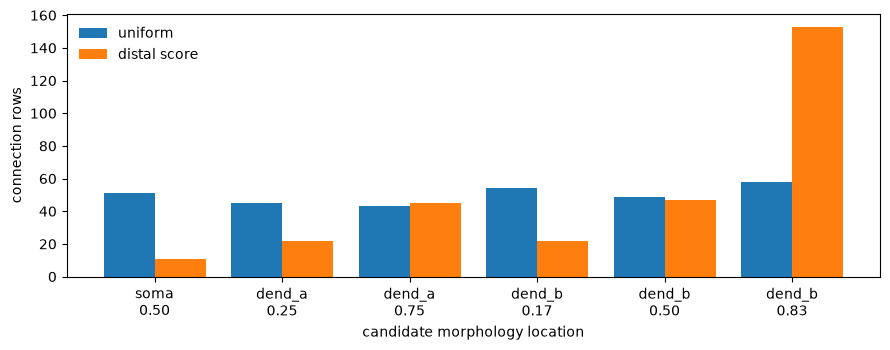

In [10]:
def target_hits(view):
    return np.bincount(view.target_index, minlength=len(sampled_targets))


location_hits = pd.DataFrame({
    "branch": branch_names[sampled_targets.branch_id],
    "branch_x": sampled_targets.branch_x,
    "uniform": target_hits(uniform_pairs),
    "distal score": target_hits(distal_pairs),
}).groupby(["branch", "branch_x"], sort=False, as_index=False).sum()

x = np.arange(len(location_hits))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, location_hits["uniform"], 0.4, label="uniform")
ax.bar(x + 0.2, location_hits["distal score"], 0.4, label="distal score")
ax.set(
    ylabel="connection rows", xlabel="candidate morphology location",
    xticks=x,
    xticklabels=[f"{b}\n{x:.2f}" for b, x in zip(location_hits.branch, location_hits.branch_x)],
)
ax.legend(frameon=False)
fig.tight_layout()

### 5.2 Conditional sampling: a 3-D source–synapse distance kernel

`source_first` draws the sources first, then scores every synapse candidate separately for each source drawn. A `NetStim` has no spatial fields, so `source_positions` gives them explicitly, indexed by `ctx.source.id`; the synapse coordinates come straight from the morphology:

$$q_{sj}=\exp\left[-\frac{1}{2}\left\|\frac{x_s-x_j}{25\,\mu m}\right\|^2\right].$$

`ctx.source.id` has shape `(B, 1)` and `ctx.synapse.position` has shape `(1, K, 3)`; their difference is `(B, K, 3)`, and the sum over the coordinate axis gives the `(B, K)` score.

In [11]:
def spatial_synapse_score(ctx):
    delta = (source_positions[ctx.source.id] - ctx.synapse.position) / (25.0 * u.um)
    return u.math.exp(-0.5 * u.math.sum(delta**2, axis=-1))


spatial_pairs = braincell.connect(
    "spatial_pairs", source=pairing_source, synapse=sampled_targets,
    pairing=braincell.network.connection.source_first(
        300, synapse_score=spatial_synapse_score, seed=22,
    ),
    weight=0.08 * u.uS,
)


def nearby_branch_fraction(view):
    expected_branch = np.where(view.source_index < 2, 1, 2)
    return np.mean(view.synapse.branch_id == expected_branch)


uniform_nearby = nearby_branch_fraction(uniform_pairs)
spatial_nearby = nearby_branch_fraction(spatial_pairs)
assert spatial_nearby > 0.8
assert spatial_nearby > uniform_nearby
pd.DataFrame({
    "pairing": ["uniform", "3-D distance kernel"],
    "rows": [len(uniform_pairs), len(spatial_pairs)],
    "fraction on nearby dendrite": [uniform_nearby, spatial_nearby],
})

,pairing,rows,fraction on nearby dendrite
0,uniform,300,0.420000
1,3-D distance kernel,300,0.863333


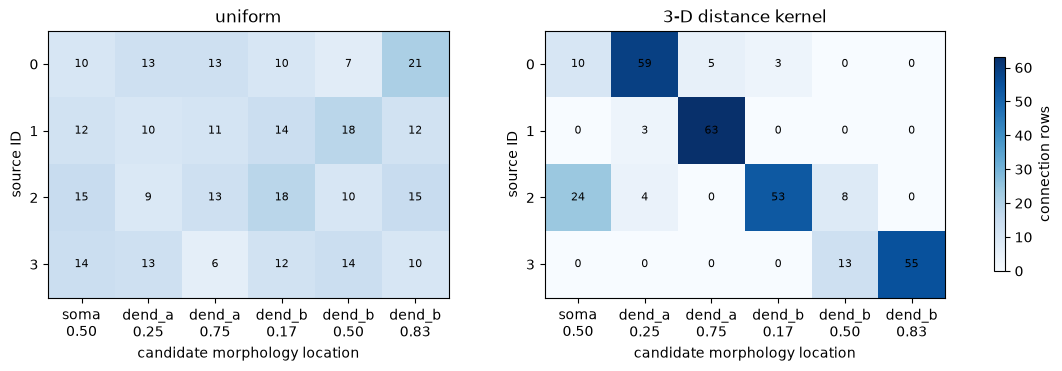

In [12]:
location_keys = list(dict.fromkeys(
    zip(sampled_targets.branch_id.tolist(), sampled_targets.branch_x.tolist())
))
location_lookup = {key: index for index, key in enumerate(location_keys)}
candidate_location_index = np.asarray([
    location_lookup[key]
    for key in zip(sampled_targets.branch_id.tolist(), sampled_targets.branch_x.tolist())
])
location_labels = [f"{branch_names[b]}\n{x:.2f}" for b, x in location_keys]


def location_count_matrix(view):
    matrix = np.zeros((4, len(location_keys)), dtype=int)
    np.add.at(matrix, (view.source_index, candidate_location_index[view.target_index]), 1)
    return matrix


matrices = [location_count_matrix(uniform_pairs), location_count_matrix(spatial_pairs)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for ax, matrix, title in zip(axes, matrices, ["uniform", "3-D distance kernel"]):
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(m.max() for m in matrices))
    for source_id, location_id in np.ndindex(matrix.shape):
        ax.text(location_id, source_id, matrix[source_id, location_id],
                ha="center", va="center", fontsize=8)
    ax.set(
        xlabel="candidate morphology location", ylabel="source ID", title=title,
        xticks=np.arange(len(location_keys)), xticklabels=location_labels,
        yticks=np.arange(4),
    )
fig.colorbar(image, ax=axes, label="connection rows", shrink=0.8)

### 5.3 Morphology-dependent heterogeneous in-degree

`by_synapse` first draws an in-degree for each synapse, then picks a source for each row. Here distal synapses get a higher expected in-degree:

$$d_j=1+\operatorname{Poisson}\left(0.25+\frac{d_{\mathrm{soma},j}}{120\,\mu m}\right).$$

The sources' `start` parameter then gives the preference $q_s=\exp[-(start_s-50\,ms)/(20\,ms)]$. A random in-degree can exceed the four sources, so `replace=True` is used; the same source–synapse pair can then have several routing records.

In [13]:
def morphology_degree(ctx, rng):
    distance_um = np.asarray(ctx.synapse.path_distance_from_soma.to_decimal(u.um))
    rate = 0.25 + distance_um / 120.0
    return 1 + np.asarray(rng.poisson(rate, size=rate.shape), dtype=np.int64)


def early_source_score(ctx):
    start = ctx.source.get("start")
    return u.math.exp(-(start - 50.0 * u.ms) / (20.0 * u.ms))


degree_pairs = braincell.connect(
    "heterogeneous_degree_pairs",
    source=pairing_source, synapse=sampled_targets,
    pairing=braincell.network.connection.by_synapse(
        morphology_degree, source_score=early_source_score,
        replace=True, seed=23,
    ),
    weight=0.06 * u.uS,
)

actual_degree = np.bincount(degree_pairs.target_index, minlength=len(sampled_targets))
source_rows = np.bincount(degree_pairs.source_index, minlength=4)
assert actual_degree.min() >= 1
assert actual_degree.sum() == len(degree_pairs)
assert source_rows[0] > source_rows[-1]

degree_table = pd.DataFrame({
    "target cell": sampled_targets.population_index,
    "branch": branch_names[sampled_targets.branch_id],
    "branch_x": sampled_targets.branch_x,
    "actual in-degree": actual_degree,
})
source_table = pd.DataFrame({
    "source ID": np.arange(4),
    "start (ms)": pairing_source.start.to_decimal(u.ms),
    "connection rows": source_rows,
})
display(source_table)
degree_table

,source ID,start (ms),connection rows
0,0,50.0,21
1,1,60.0,12
2,2,70.0,5
3,3,80.0,2


,target cell,branch,branch_x,actual in-degree
0,0,soma,0.500000,1
1,0,dend_a,0.250000,2
2,0,dend_a,0.750000,2
3,0,dend_b,0.166667,1
4,0,dend_b,0.500000,4
5,0,dend_b,0.833333,2
6,1,soma,0.500000,1
7,1,dend_a,0.250000,1
8,1,dend_a,0.750000,1
9,1,dend_b,0.166667,2


[Text(0.5, 0, 'source ID'),
 Text(0, 0.5, 'connection rows'),
 Text(0.5, 1.0, 'source preference from NetStim.start'),

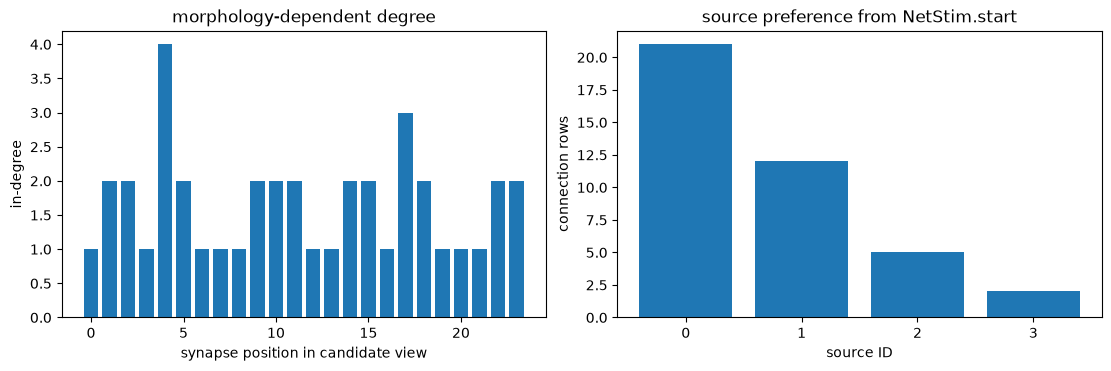

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].bar(np.arange(len(actual_degree)), actual_degree)
axes[0].set(
    xlabel="synapse position in candidate view",
    ylabel="in-degree", title="morphology-dependent degree",
)
axes[1].bar(np.arange(4), source_rows)
axes[1].set(
    xlabel="source ID", ylabel="connection rows",
    title="source preference from NetStim.start", xticks=np.arange(4),
)

## 6. Delivering scheduled sources, weights and delays

| source | where the times come from | other Cells to advance? |
|---|---|---|
| `EventSequence` | the user's `EventTable` | no |
| `NetStim` | the schedule from start/interval/number/noise | no |
| `cell.event_outputs["spike"]` | canonical root-CV threshold crossing | yes, the Network schedules the source owner |
| `VoltageCrossingSource` | given location, threshold and direction | yes, the Network schedules the source owner |

This section uses only deterministic scheduled sources. Event times and delays are quantized to simulation boundaries:

$$t_{\mathrm{arrival}}=\operatorname{round\_half\_up}\!\left(\frac{t_{\mathrm{event}}+d_c}{dt}\right)dt.$$

All times here fall exactly on `dt=0.025 ms` boundaries, so the observed values should equal `event time + delay` exactly. `post.record()` records the conductance of `scheduled_syn` with `observe.synapse(name=...).state("g")`, one row per population member. A recording samples before each step: row `k` is the state at `result.time[k]`, so an event delivered on the step that starts at its arrival time first shows in the next sample.

In [15]:
sequence = braincell.EventSequence(
    size=4,
    events=braincell.EventTable(
        source_index=[0, 1, 2, 3],
        time=np.asarray([1.0, 1.5, 2.0, 2.5]) * u.ms,
    ),
    name="explicit_schedule",
)
scheduled_syn = mech.Synapse(
    "ExpSyn", name="scheduled_syn", tau=3.0 * u.ms, e=0.0 * u.mV,
)
post.place(at("dend_a", 0.50), scheduled_syn)
post.record("g_scheduled", braincell.observe.synapse(name="scheduled_syn").state("g"))
scheduled_connection = braincell.connect(
    "scheduled_input",
    source=sequence, synapse=post.synapses[scheduled_syn],
    weight=np.asarray([0.10, 0.20, 0.30, 0.40]) * u.uS,
    delay=np.asarray([0.0, 0.25, 0.50, 0.75]) * u.ms,
)

pd.DataFrame({
    "event_id": sequence.events.event_id,
    "source_id": sequence.events.source_index,
    "event_ms": sequence.events.time.to_decimal(u.ms),
    "weight_uS": scheduled_connection.weight.to_decimal(u.uS),
    "delay_ms": scheduled_connection.delay.to_decimal(u.ms),
})

,event_id,source_id,event_ms,weight_uS,delay_ms
0,0,0,1.0,0.1,0.00
1,1,1,1.5,0.2,0.25
2,2,2,2.0,0.3,0.50
3,3,3,2.5,0.4,0.75


In [16]:
result = post.run(dt=0.025 * u.ms, duration=4.0 * u.ms)
# run() initialized the Cell: views selected before it are stale, so select the rows again.
scheduled_connection = post.connections["scheduled_input"]
time_ms = result.time.to_decimal(u.ms)
g = np.asarray(result.traces["g_scheduled"].to_decimal(u.uS))

first_nonzero = np.asarray([
    np.flatnonzero(g[:, cell_id] > 0.0)[0] for cell_id in range(4)
])
# A recording samples before each step: the event delivered on the step that
# starts at the arrival time first shows in the next sample.
observed_arrival_ms = time_ms[first_nonzero - 1]
expected_arrival_ms = np.asarray([1.0, 1.75, 2.50, 3.25])
np.testing.assert_allclose(observed_arrival_ms, expected_arrival_ms, atol=1e-12)
assert np.all(np.diff(g.max(axis=0)) > 0.0)

arrival_table = pd.DataFrame({
    "source_id": np.arange(4),
    "event_ms": sequence.events.time.to_decimal(u.ms),
    "delay_ms": scheduled_connection.delay.to_decimal(u.ms),
    "expected_arrival_ms": expected_arrival_ms,
    "observed_arrival_ms": observed_arrival_ms,
    "peak_g_uS": g.max(axis=0),
})
arrival_table

,source_id,event_ms,delay_ms,expected_arrival_ms,observed_arrival_ms,peak_g_uS
0,0,1.0,0.00,1.00,1.00,0.099170
1,1,1.5,0.25,1.75,1.75,0.198340
2,2,2.0,0.50,2.50,2.50,0.297510
3,3,2.5,0.75,3.25,3.25,0.396681


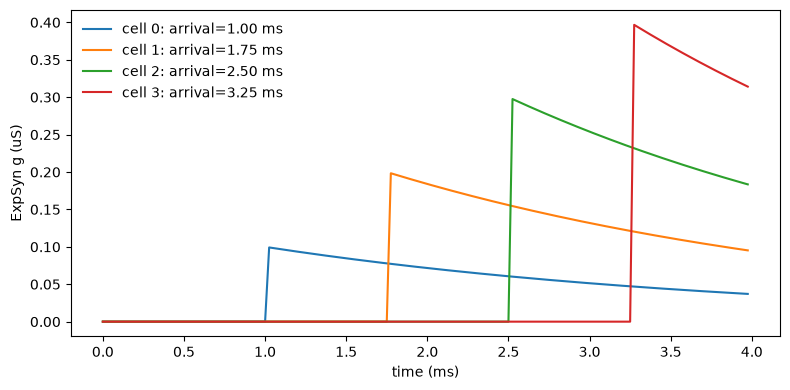

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
for cell_id in range(4):
    ax.plot(
        time_ms, g[:, cell_id],
        label=f"cell {cell_id}: arrival={observed_arrival_ms[cell_id]:.2f} ms",
    )
ax.set(xlabel="time (ms)", ylabel="ExpSyn g (uS)")
ax.legend(frameon=False)
fig.tight_layout()

### Changing weights after initialization

After `init_state()` (here the first `run()`) the routing and the delays are fixed, but `.set(weight=...)` still changes the weights of existing rows. Select the rows again first: views made before initialization are stale. An event already sent and still in its delay takes the weight it arrives with, as NEURON's `NetCon` does, so a `set` between two runs also reaches the events in flight.

In [18]:
explicit = post.connections["explicit_input"]
explicit[[2, 0]].set(weight=np.asarray([0.25, -0.10]) * u.uS)

try:
    explicit.set(delay=1.0 * u.ms)
except RuntimeError as error:
    print("RuntimeError:", error)

np.testing.assert_allclose(np.asarray(explicit.weight.to_decimal(u.uS))[[2, 0]], [0.25, -0.10])
connection_frame(explicit)

RuntimeError: Connection delay is structural; configure it in connect() before init_state().


,id,source,synapse,target_cell,weight_uS,delay_ms
0,12,2,13,1,-0.10,0.0
1,14,2,13,1,-0.05,1.0
2,15,1,12,0,0.25,1.5


## Summary

- `connect()` lowers concrete EventSource endpoints and existing logical synapses to one routing record per row.
- Equal-length zip, singleton broadcasting and explicit repeated views make a deterministic general mapping; `pairing=` samples the same kind of rows from candidate views without repeats.
- A score turns the source, morphology and synapse parameters in `ctx` into discrete selection probabilities; a degree sets how many rows each fixed endpoint gets.
- `ConnectionView` filters by connect call, source, synapse and target cell, then reads, removes or reweights rows.
- `weight` and `delay` belong to the Connection, synapse dynamics parameters and states to the Synapse; several rows may share one synapse.
- `EventSequence` and `NetStim` can be consumed directly by the target Cell; live sources from other Cells need a Network that advances the source owner together with the target.
- After initialization the topology and the delays are fixed and `.set(weight=...)` can still change weights; running advances only the states, the time and the delay queues.